<!-- DRAFT: Graeme to edit -->
# Day 2 · 07b (full data) — Lab: two newer foundation models against Chronos-2 (20 min)

07 found Chronos-2, zero-shot with the price and promotion covariates, the most accurate
model on the board. Two open-weight models released in October 2026 claim to beat it on
public benchmarks: **Timestral** (Mistral AI, 209M parameters) and **t0-gamma** (The
Forecasting Company, 256M). Both run on our own GPU, like Chronos-2, with no training.

Public benchmarks are not this shop. So we run all three models the same way, on the same
2,000 evaluation series and windows, with four covariate setups, and ask four questions:
are the new ones more accurate, is the gap real, where do they fail, and do they respond to
a planned discount?

Goals

1. Run Chronos-2, Timestral and t0-gamma with four covariate setups, on validation and test.
2. Score the test window once, and test whether the gaps are larger than chance.
3. Look at the hard weeks: events, promotions and sales above anything in the history.
4. Probe each model's price response with the phase 7b probes.

**In the chain:** reads the selected config (`gd.selected_config()`), `07_foundation` and
`05b_synthetic` (the GFM's probes), writes `07b_new_foundation`.

In [1]:
import functools

import numpy as np
import pandas as pd
import torch
from scipy import stats

import gd_helpers as gd
import gd_plots as gplt
import gd_price as gp

bc = gd.bc
gd.status()
gplt.use_style()

/home/gdavidson/code/time-series-forecasting-bootcamp/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LOAD (read saved results) | results: results/day2_full | accelerator: gpu


<!-- DRAFT: Graeme to edit -->
## Intuition: three travelling consultants

All three models have seen many series from many industries, and none of them this shop.
Each reads one series' history, and the plan for its price and promotions, and forecasts the
next 14 weeks. They differ in how they were trained and on what. Public leaderboards rank
them on other people's data; the only way to know which reads *this* shop best is to ask
them all the same questions.

<!-- DRAFT: Graeme to edit -->
## 1. Settings

* Each model runs with the developers' recommended settings: symmetric averaging (each
  forecast averaged with the mirrored forecast of the negated series), and clipping at 0
  for a series that never went negative. Sales cannot be negative, so the clipping stays on.
* Zero-shot forecasts have no seed: the same input always gives the same forecast.
* A smoke run forecasts 20 series on the CPU.

In [2]:
GPU = torch.cuda.is_available()
FM_N_SERIES = 20 if gd.SMOKE else None        # None: every eval series
MODELS = {"Chronos2": "chronos", "Timestral": "timestral", "T0gamma": "t0"}
BOARD_NAMES = {"Timestral": "Timestral_zs_cov", "T0gamma": "T0gamma_zs_cov",
               "Chronos2": "Chronos2_zs_cov"}
print(f"GPU: {GPU} | models: {list(MODELS)}")


@functools.cache
def load(name: str):
    """Each model once, on the GPU when there is one."""
    kind = MODELS[name]
    if kind == "chronos":
        return gd.chronos_pipeline()
    return gd.foundation_model(kind)


def forecast(name: str, hist: pd.DataFrame, future: pd.DataFrame | None, covariates: list[str],
             alias: str) -> pd.DataFrame:
    """``name``'s zero-shot forecast of the ``H`` weeks after ``hist``: point and 80% band."""
    cols = ["unique_id", "ds", "y"] + covariates
    futr = future[["unique_id", "ds"] + covariates] if covariates else None
    if MODELS[name] == "chronos":
        out = gd.chronos_forecast(load(name), hist[cols], futr, alias=alias,
                                  quantiles=gd.CHRONOS_QUANTILES)
    else:
        out = gd.foundation_forecast(MODELS[name], load(name), hist[cols], futr, alias=alias,
                                     covariates=covariates)
    keep = ["unique_id", "ds", alias, f"{alias}-lo-80", f"{alias}-hi-80"]
    out = out[keep]
    out[keep[2:]] = out[keep[2:]].clip(lower=0)
    return out

GPU: True | models: ['Chronos2', 'Timestral', 'T0gamma']


<!-- DRAFT: Graeme to edit -->
## 2. Data and the four covariate setups

`gp.prepare` rebuilds the selected config's data, as in 07, for the test window and, with
`cutoff=bc.VALID_START`, for validation. The context is each series' full training history.

| Setup | Covariates |
|---|---|
| `none` | none: sales history only |
| `price` | the selected config's: `promo`, `discount_depth`, `price_index` |
| `price_events` | `price` and one dummy per retail event week |
| `everything` | `price_events`, the rolling price ratio, the weekly price change, and two |
| | pairs of yearly sine and cosine terms |

**The main setup is `price`, fixed before any result:** it is 07's `Chronos2_zs_cov`. Only
each model's `price` run goes on the board and to notebook 10; the other setups are
reported here. `everything` is the kind of feature set built for tree models.

In [3]:
cfg = gd.selected_config()
fm07_cfg = gd.load_config("07_foundation")
synthetic_cfg = gd.load_config("05b_synthetic")
baselines_cfg = gd.load_config("00_baselines")
noise_floor = gd.load_config("02_shortlist")["noise_floor"]
raw = gp.add_fourier(gp.add_events(gd.train_panel()), 2)
synthetic_seed = cfg.get("synthetic_seed")
panel, train, test, data = gp.prepare(cfg, panel=raw, synthetic_seed=synthetic_seed)
_, fit_part, valid, _ = gp.prepare(cfg, panel=raw, synthetic_seed=synthetic_seed,
                                   cutoff=bc.VALID_START)
info = gplt.series_table(panel)
price_cols = cfg["futr_exog"]
SETUPS = {
    "none": [],
    "price": price_cols,
    "price_events": price_cols + gp.EVENT_COLS,
    "everything": price_cols + gp.EVENT_COLS + ["price_ratio_to_rolling_mean",
                                                "price_pct_change_1w"] + gp.fourier_cols(2),
}
MAIN_SETUP = "price"
all_covs = SETUPS["everything"]

fm_ids = gd.eval_ids()
if FM_N_SERIES:
    fm_ids = fm_ids[:FM_N_SERIES]
WINDOWS = {"valid": (gd.only(bc.to_nixtla(fit_part, all_covs), fm_ids),
                     gd.only(bc.to_nixtla(valid, all_covs).drop(columns="y"), fm_ids)),
           "test": (gd.only(bc.to_nixtla(train, all_covs), fm_ids),
                    gd.only(bc.to_nixtla(test, all_covs).drop(columns="y"), fm_ids))}
print(f"{len(fm_ids):,} series | setups: {list(SETUPS)} | main: {MAIN_SETUP}")

2,000 series | setups: ['none', 'price', 'price_events', 'everything'] | main: price


<!-- DRAFT: Graeme to edit -->
## 3. Every model, every setup, both windows

3 models × 4 setups × 2 windows = 24 forecasts, each cached with the seconds it took.

In [4]:
def run(name: str, setup: str, window: str):
    """One model, setup and window, timed."""
    def compute() -> pd.DataFrame:
        hist, future = WINDOWS[window]
        with bc.Timer() as t:
            out = forecast(name, hist, future, SETUPS[setup], f"{name}_{setup}")
        print(f"{window:5s} {name:9s} {setup:12s} {t.seconds:6.1f}s")
        return out.assign(seconds=t.seconds)
    return compute


fc = {"valid": None, "test": None}
seconds = {}
for window in fc:
    for name in MODELS:
        for setup in SETUPS:
            out = gd.cached(f"07b_fc_{name}_{setup}_{window}", run(name, setup, window))
            out["ds"] = pd.to_datetime(out["ds"])
            seconds[f"{name}_{setup}_{window}"] = float(out.pop("seconds").iloc[0])
            fc[window] = out if fc[window] is None else fc[window].merge(
                out, on=["unique_id", "ds"])
RUNS = [f"{name}_{setup}" for name in MODELS for setup in SETUPS]

<!-- DRAFT: Graeme to edit -->
First, a check: the Chronos-2 `price` run must reproduce 07's `Chronos2_zs_cov` forecasts,
or the comparison below is not like for like.

In [5]:
stored = pd.read_parquet(gd.FORECAST_DIR / "07_foundation.parquet")
stored["ds"] = pd.to_datetime(stored["ds"])
same = fc["test"][["unique_id", "ds", "Chronos2_price"]].merge(
    stored[["unique_id", "ds", "Chronos2_zs_cov"]], on=["unique_id", "ds"])
chronos_gap = float((same["Chronos2_price"] - same["Chronos2_zs_cov"].clip(lower=0)).abs().max())
print(f"Chronos-2 price run against 07's Chronos2_zs_cov, largest difference (units): "
      f"{chronos_gap:.4f}")

Chronos-2 price run against 07's Chronos2_zs_cov, largest difference (units): 0.0000


<!-- DRAFT: Graeme to edit -->
## 4. Validation: which setup suits each model?

Median RMSSE per model (rows) and setup (columns) on the validation window. The main setup
is fixed already; this table shows whether another setup would have served a model better.

In [6]:
def median_table(window: str, actual, history) -> pd.DataFrame:
    """Median RMSSE, models as rows, setups as columns."""
    per = gd.per_series(gd.score(fc[window][["unique_id", "ds"] + RUNS], actual, history))
    med = per.median()
    return pd.DataFrame({setup: {name: med[f"{name}_{setup}"] for name in MODELS}
                         for setup in SETUPS})


valid_table = median_table("valid", valid, fit_part)
valid_table.round(3)

,none,price,price_events,everything
Chronos2,0.701,0.575,0.575,0.581
Timestral,0.688,0.557,0.548,0.544
T0gamma,0.703,0.536,0.531,0.547


<!-- DRAFT: Graeme to edit -->
## 5. The test window

The same table on test, then each model's main setup on the board, next to the GFM and
LightGBM.

In [7]:
test_table = median_table("test", test, train)
test_table.round(3)

,none,price,price_events,everything
Chronos2,0.645,0.512,0.531,0.536
Timestral,0.639,0.523,0.518,0.513
T0gamma,0.652,0.502,0.501,0.509


In [8]:
NEW = ["Timestral", "T0gamma"]
board = fc["test"][["unique_id", "ds"] + [f"{n}_{MAIN_SETUP}" for n in NEW]]
board = board.rename(columns={f"{n}_{MAIN_SETUP}": BOARD_NAMES[n] for n in NEW})
gd.save_forecasts(board, "07b_new_foundation")
gd.record(board, test, train, lab="07b new foundation",
          fit_seconds={BOARD_NAMES[n]: seconds[f"{n}_{MAIN_SETUP}_test"] for n in NEW},
          notes=f"{len(fm_ids)} series; zero-shot; covariates {price_cols}")

baselines = pd.read_parquet(gd.FORECAST_DIR / "00_baselines.parquet")
baselines["ds"] = pd.to_datetime(baselines["ds"])
main = fc["test"][["unique_id", "ds"] + [f"{n}_{MAIN_SETUP}" for n in MODELS]]
main = main.rename(columns={f"{n}_{MAIN_SETUP}": BOARD_NAMES[n] for n in MODELS})
both = main.merge(gd.selected_forecasts(cfg), on=["unique_id", "ds"], how="left")
both = both.merge(baselines[["unique_id", "ds", "LightGBM", "SeasonalNaive"]],
                  on=["unique_id", "ds"], how="left")
test_metrics = gd.score(both, test, train)
rmsse = gd.per_series(test_metrics)
test_summary = bc.summarise(test_metrics, both, test).sort_values("median_rmsse")
test_summary[["model", "median_rmsse", "mean_rmsse", "wape", "n_series"]].round(3)

,model,median_rmsse,mean_rmsse,wape,n_series
1,T0gamma_zs_cov,0.502,1.064,0.206,1999
3,Chronos2_zs_cov,0.512,1.081,0.217,1999
0,Timestral_zs_cov,0.523,1.034,0.227,1999
2,GFM_selected,0.546,1.067,0.257,1999
4,LightGBM,0.569,1.161,0.295,1999
5,SeasonalNaive,0.929,1.525,0.438,1999


<!-- DRAFT: Graeme to edit -->
The board so far: this notebook and the ones before it.

In [9]:
gd.median_board("07b")

,model,median_rmsse,mean_rmsse,wape,n_series,lab,fit_seconds
0,T0gamma_zs_cov,0.502,1.064,0.206,1999,07b new foundation,6.001
1,Chronos2_zs_cov,0.512,1.081,0.217,1999,07 foundation,2.960
2,Timestral_zs_cov,0.523,1.034,0.227,1999,07b new foundation,12.805
3,NHITS_recipe_mean,0.539,1.063,0.251,1999,01 recipe (3-seed mean),249.433
4,NBEATSx_B_cpi_mean,0.540,1.076,0.263,1999,04 price arms (3-seed mean),522.767
5,GFM_synthetic,0.546,1.768,0.265,1999,05b synthetic (3-seed mean),361.200
6,GFM_selected,0.546,1.067,0.257,1999,05 selected (3-seed mean),379.767
7,GFM_cluster_static,0.551,1.086,0.268,1999,06 clusters (3-seed mean),367.433
8,NBEATSx_C_cpi_over_mean,0.553,1.073,0.267,1999,04 price arms (3-seed mean),575.033
9,NBEATSx_A_features_mean,0.568,1.114,0.286,1999,04 price arms (3-seed mean),501.467


<!-- DRAFT: Graeme to edit -->
### Reading the result

* **t0-gamma is the most accurate model on the board**: median RMSSE 0.502 on test, against
  0.512 for Chronos-2 and 0.523 for Timestral. It also led on validation (0.536, 0.575,
  0.557), so the order did not change between windows.
* **The price inputs do the work.** Without them every model scores ≈ 0.70 on validation and
  ≈ 0.64 on test; with them, ≈ 0.54–0.58 and ≈ 0.50–0.52.
* **The extra inputs matter little.** Event dummies and the tree-style columns move each
  model by 0.025 or less, in no consistent direction: they help Timestral a little on both
  windows (0.523 → 0.513 on test) and hurt Chronos-2 on test (0.512 → 0.537). Public tests
  found tree-style features hurt these models; here they are close to neutral.

*Exact numbers vary with hardware.*

<!-- DRAFT: Graeme to edit -->
## 6. Is the gap real?

Two series can disagree by chance. For each pair, the **Wilcoxon signed-rank test** asks
whether one model's per-series RMSSE is lower than the other's more often, and by more, than
chance would give. The **noise floor** is how much one model's median RMSSE moved between
three training seeds in 02: a smaller gap could be the luck of a seed. A difference counts
as **real** only when both hold: the gap is larger than the noise floor, and the p-value is
below 0.05.

In [10]:
def paired(a: str, b: str) -> dict:
    """Median-RMSSE gap and Wilcoxon p-value for ``a`` against ``b`` (same series)."""
    pair = rmsse[[a, b]].dropna()
    return {"model": a, "against": b, "gap (median)": pair[a].median() - pair[b].median(),
            "p (Wilcoxon)": stats.wilcoxon(pair[a], pair[b]).pvalue,
            "share of series better": float((pair[a] < pair[b]).mean()),
            "real difference": bool(abs(pair[a].median() - pair[b].median()) > noise_floor
                                    and stats.wilcoxon(pair[a], pair[b]).pvalue < 0.05)}


pairs_tested = []
for new in (BOARD_NAMES["Timestral"], BOARD_NAMES["T0gamma"]):
    for ref in (BOARD_NAMES["Chronos2"], "GFM_selected"):
        pairs_tested.append(paired(new, ref))
pairs_tested.append(paired(BOARD_NAMES["Timestral"], BOARD_NAMES["T0gamma"]))
wilcoxon = pd.DataFrame(pairs_tested)
wilcoxon.round(4)

,model,against,gap (median),p (Wilcoxon),share of series better,real difference
0,Timestral_zs_cov,Chronos2_zs_cov,0.0103,0.8826,0.4867,False
1,Timestral_zs_cov,GFM_selected,-0.0237,0.0000,0.5433,True
2,T0gamma_zs_cov,Chronos2_zs_cov,-0.0099,0.0000,0.5408,True
3,T0gamma_zs_cov,GFM_selected,-0.0439,0.0000,0.5868,True
4,Timestral_zs_cov,T0gamma_zs_cov,0.0202,0.0001,0.4592,True


<!-- DRAFT: Graeme to edit -->
### Reading the result

* **t0-gamma against Chronos-2 is a real difference**: 0.010 lower, twice the noise floor,
  p ≈ 0, and better on 54% of series.
* **Timestral against Chronos-2 is not.** Its median is 0.010 higher, but p = 0.88: on a
  per-series basis there is no consistent winner.
* Both new models beat the selected GFM (by 0.024 and 0.044), and t0-gamma beats Timestral.

*Exact numbers vary with hardware.*

<!-- DRAFT: Graeme to edit -->
## 7. The hard weeks, defined before the results

A median over 14 weeks hides where a model fails. We split the test weeks into groups, all
known before looking, and compare the **scaled error** in each: the absolute error divided
by the series' usual 52-week seasonal-naive error in training (the same scale as RMSSE), so
small and large series count alike.

* **event weeks**: Good Friday, Anzac Day and Mother's Day (test weeks 1, 2 and 4);
* **promo weeks**: weeks with a planned promotion;
* **above the history**: weeks whose sales beat the series' largest training week;
* **classes A–I** against **class J**, the low sellers.

In [11]:
hist_y = train.select("unique_id", "ds", "y").to_pandas()
hist_y["ds"] = pd.to_datetime(hist_y["ds"])
hist_y = hist_y.sort_values(["unique_id", "ds"])
hist_y["lag52"] = hist_y.groupby("unique_id")["y"].shift(52)
scale = (hist_y["y"] - hist_y["lag52"]).abs().groupby(hist_y["unique_id"]).mean()
train_max = hist_y.groupby("unique_id")["y"].max()

actual = bc.to_nixtla(test, ["promo"])
actual["ds"] = pd.to_datetime(actual["ds"])
cells = both.merge(actual, on=["unique_id", "ds"])
cells["scale"] = cells["unique_id"].map(scale)
cells = cells[cells["scale"] > 0]
hard_models = [BOARD_NAMES[n] for n in MODELS] + ["GFM_selected", "LightGBM"]
events = gp.event_weeks(cells["ds"])
sale_class = cells["unique_id"].map(info["sale_class"])
GROUPS = {
    "all weeks": pd.Series(True, index=cells.index),
    "event weeks": cells["ds"].isin(events),
    "promo weeks": cells["promo"] > 0,
    "above the history": cells["y"] > cells["unique_id"].map(train_max),
    "classes A-I": sale_class != "J",
    "class J": sale_class == "J",
}
scaled = cells[hard_models].sub(cells["y"], axis=0).abs().div(cells["scale"], axis=0)
hard = pd.DataFrame({group: scaled[mask].mean() for group, mask in GROUPS.items()}).T
hard.insert(0, "weeks", [int(mask.sum()) for mask in GROUPS.values()])
hard.round(3)

,weeks,Chronos2_zs_cov,Timestral_zs_cov,T0gamma_zs_cov,GFM_selected,LightGBM
all weeks,27986,2.745,2.505,2.729,2.536,2.970
event weeks,5997,1.609,1.471,1.488,1.449,1.761
promo weeks,6831,3.669,3.355,3.810,3.472,3.996
above the history,943,58.782,52.146,60.603,51.006,62.874
classes A-I,9520,0.614,0.616,0.583,0.727,0.785
class J,18466,3.844,3.478,3.835,3.468,4.096


<!-- DRAFT: Graeme to edit -->
The gap to Chronos-2 in each group (positive: worse than Chronos-2).

In [12]:
hard[hard_models].sub(hard[BOARD_NAMES["Chronos2"]], axis=0).drop(
    columns=BOARD_NAMES["Chronos2"]).round(3)

,Timestral_zs_cov,T0gamma_zs_cov,GFM_selected,LightGBM
all weeks,-0.241,-0.016,-0.210,0.225
event weeks,-0.138,-0.121,-0.160,0.152
promo weeks,-0.314,0.141,-0.198,0.326
above the history,-6.636,1.822,-7.776,4.093
classes A-I,0.002,-0.031,0.113,0.171
class J,-0.366,-0.009,-0.376,0.252


<!-- DRAFT: Graeme to edit -->
### Reading the result

* **Timestral is best on the hard weeks.** Among the foundation models it has the lowest
  scaled error on promo weeks (3.36, against 3.67 for Chronos-2 and 3.81 for t0-gamma),
  on event weeks (1.47) and on weeks above the history (52, against 59 and 61).
* **t0-gamma wins where the sales are.** It is best on classes A–I (0.58, against 0.61 for
  both others), and worst of the three on promo and above-history weeks.
* **Class J dominates the averages.** It holds two thirds of the weeks, and its scaled
  errors are large because its usual error is small. That is why the "all weeks" row ranks
  the models differently from the median RMSSE.
* The GFM is close to Timestral on every hard group, and the best of all on event weeks
  (1.45) and above the history (51).

*Exact numbers vary with hardware.*

<!-- DRAFT: Graeme to edit -->
## 8. How much history? (report only)

The main setup with the last 13, 26 and 52 weeks of history, and with all of it (≈ 93).
Public tests found Timestral gains from very long histories; ours are short.

All three need all of it: with 13 or 26 weeks each scores ≈ 0.59–0.63, with 52 weeks
≈ 0.53, and with the full history 0.50–0.52. A model that cannot see last year's same weeks
cannot see the seasonal pattern.

In [13]:
HISTORIES = [13, 26, 52, None]


def run_history(name: str, weeks: int | None):
    """The main setup on test, with only the last ``weeks`` of history."""
    def compute() -> pd.DataFrame:
        hist, future = WINDOWS["test"]
        if weeks:
            hist = hist.groupby("unique_id").tail(weeks)
        alias = f"{name}_h{weeks or 'all'}"
        return forecast(name, hist, future, SETUPS[MAIN_SETUP], alias)[["unique_id", "ds",
                                                                         alias]]
    return compute


history_rows = {}
for name in MODELS:
    frames = None
    for weeks in HISTORIES:
        if weeks is None:
            out = fc["test"][["unique_id", "ds", f"{name}_{MAIN_SETUP}"]].rename(
                columns={f"{name}_{MAIN_SETUP}": f"{name}_hall"})
        else:
            out = gd.cached(f"07b_hist_{name}_{weeks}", run_history(name, weeks))
            out["ds"] = pd.to_datetime(out["ds"])
        frames = out if frames is None else frames.merge(out, on=["unique_id", "ds"])
    med = gd.per_series(gd.score(frames, test, train)).median()
    history_rows[name] = {f"{w or 'all'} weeks": med[f"{name}_h{w or 'all'}"] for w in HISTORIES}
history = pd.DataFrame(history_rows).T
history.round(3)

,13 weeks,26 weeks,52 weeks,all weeks
Chronos2,0.600,0.600,0.534,0.512
Timestral,0.630,0.619,0.534,0.523
T0gamma,0.593,0.594,0.528,0.502


<!-- DRAFT: Graeme to edit -->
## 9. Price response: do they read the planned price?

The same probes as 05b and 07, on the same report series: one-week and sustained price
shocks with every price input rebuilt, and five random promotion calendars per series
(`gp.price_probes`, `gp.promo_calendars`). Each model forecasts with the main setup.

In [14]:
probe_ids = gp.report_ids(train, fm_ids)
probe_hist = gd.only(bc.to_nixtla(train, price_cols), probe_ids)
probe_futr = gd.only(bc.to_nixtla(test, price_cols).drop(columns="y"), probe_ids)
probe_calendars = gp.promo_calendars(probe_futr, probe_ids)
print(f"{len(probe_ids):,} report series | {len(probe_calendars):,} calendar cuts | price "
      f"inputs rebuilt, largest gap from the data: {gp.rebuild_check(probe_hist, probe_futr)}")


def predictor(name: str):
    """``predict(futr)`` for ``name`` with the main setup, on the report series."""
    def predict(futr: pd.DataFrame) -> pd.DataFrame:
        ids = sorted(futr["unique_id"].unique())
        out = forecast(name, gd.only(probe_hist, ids), futr, price_cols, "yhat")
        return out[["unique_id", "ds", "yhat"]]
    return predict


def probes(name: str, which: str):
    """The fixed probes (``probe7b``) or the calendar probes of ``name``."""
    def compute() -> pd.DataFrame:
        predict = predictor(name)
        if which == "probe7b":
            return gp.price_probes(predict, probe_hist, probe_futr, probe_ids)
        return gp.calendar_probe(predict, probe_hist, probe_futr, probe_calendars)
    return compute


probe_tables = {}
calendar_tables = {}
for name in NEW:
    key = MODELS[name]
    raw_probe = gd.cached(f"07b_{key}_probe", probes(name, "probe7b"))
    raw_calendar = gd.cached(f"07b_{key}_calendar", probes(name, "calendar"))
    probe_tables[name] = gp.probe_report(raw_probe)
    calendar_tables[name] = gp.calendar_report(raw_calendar)
chronos_probe = gp.probe_report(pd.read_parquet(gd.TABLE_DIR / "07_chronos_probe.parquet"))
chronos_calendar = gp.calendar_report(pd.read_parquet(gd.TABLE_DIR
                                                      / "07_chronos_calendar.parquet"))
gfm_key = synthetic_cfg.get("use", "05")
gfm_probe = pd.DataFrame(synthetic_cfg["probes"][gfm_key])
gfm_calendar = pd.DataFrame(synthetic_cfg["calendar"][gfm_key])

headline = pd.DataFrame({
    **{BOARD_NAMES[n]: gp.headline(probe_tables[n]) for n in NEW},
    "Chronos2_zs_cov": gp.headline(chronos_probe),
    "GFM_selected": gp.headline(gfm_probe)}).T
headline.round(3)

680 report series | 8,152 calendar cuts | price inputs rebuilt, largest gap from the data: 4.440892098500626e-16


,n,median_elasticity,median_lift,share_right_sign,share_at_bar,median_spill
Timestral_zs_cov,676.0,-1.820,0.502,0.896,0.825,-0.006
T0gamma_zs_cov,679.0,-1.188,0.304,0.907,0.785,-0.002
Chronos2_zs_cov,680.0,-1.433,0.371,0.912,0.809,-0.004
GFM_selected,680.0,-1.792,0.491,0.997,0.963,0.003


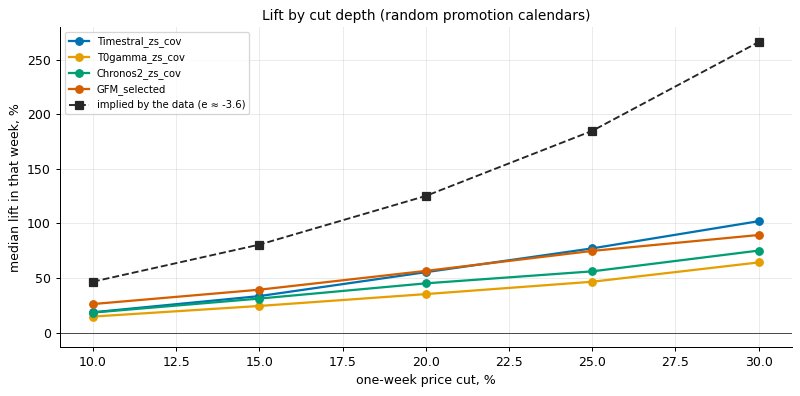

In [15]:
empirical_all = gp.empirical_elasticity(train, probe_ids).iloc[0]["elasticity"]
depths = list(gp.CAL_DEPTHS)
curves = {BOARD_NAMES[n]: calendar_tables[n].set_index("depth")["median_lift"] for n in NEW}
curves["Chronos2_zs_cov"] = chronos_calendar.set_index("depth")["median_lift"]
curves["GFM_selected"] = gfm_calendar.set_index("depth")["median_lift"]
implied = pd.Series(gp.implied_lift(empirical_all, depths), index=depths)
gplt.plot_lift_by_depth(curves, references={f"implied by the data (e ≈ {empirical_all:.1f})":
                                            implied})

<!-- DRAFT: Graeme to edit -->
### Reading the result

* **All three respond in the right direction for about 90% of series**, against 99.7% for
  the GFM. Each foundation model learns a series' response from that series alone.
* **t0-gamma responds least.** A one-week 20% cut lifts its forecast by 30% (elasticity
  −1.19), against 37% for Chronos-2, 50% for Timestral and 49% for the GFM. The data imply
  about 125%: every model under-responds.
* **Lift grows with depth for all of them.** On the random calendars, Timestral's lift goes
  from 19% at a 10% cut to 102% at 30%; t0-gamma's from 15% to 64%.
* So the most accurate model is the least price-responsive one. Accuracy rewards reading
  the usual pattern of promotions; the probes ask what a new price would do.

*Exact numbers vary with hardware.*

<!-- DRAFT: Graeme to edit -->
## 10. Averages of two (report only)

If two models fail on different series, the average of their forecasts can beat both. These
are the main-setup forecasts averaged week by week; notebook 10 builds the board's ensembles.

In [16]:
pair_list = [("Timestral_zs_cov", "T0gamma_zs_cov"), ("Timestral_zs_cov", "Chronos2_zs_cov"),
             ("T0gamma_zs_cov", "Chronos2_zs_cov"), ("Chronos2_zs_cov", "GFM_selected")]
averages = both[["unique_id", "ds"]].copy()
for a, b in pair_list:
    averages[f"{a} + {b}"] = (both[a] + both[b]) / 2
avg_rmsse = gd.per_series(gd.score(averages, test, train))
pairs = pd.DataFrame([{"pair": f"{a} + {b}", "median RMSSE": avg_rmsse[f"{a} + {b}"].median(),
                       "better model alone": min(rmsse[a].median(), rmsse[b].median()),
                       "error correlation": rmsse[a].corr(rmsse[b])} for a, b in pair_list])
pairs.round(3)

,pair,median RMSSE,better model alone,error correlation
0,Timestral_zs_cov + T0gamma_zs_cov,0.493,0.502,0.992
1,Timestral_zs_cov + Chronos2_zs_cov,0.500,0.512,0.994
2,T0gamma_zs_cov + Chronos2_zs_cov,0.492,0.502,0.996
3,Chronos2_zs_cov + GFM_selected,0.507,0.512,0.993


<!-- DRAFT: Graeme to edit -->
Every pair beats its better member: t0-gamma with Chronos-2 reaches 0.492, and t0-gamma with
Timestral 0.493, against 0.502 alone. The per-series errors are highly correlated (0.99),
so the gain comes from averaging out week-to-week noise, not from models failing on
different series.

<!-- DRAFT: Graeme to edit -->
## 11. Cost and licences

Seconds per window for 2,000 series, main setup, measured on this run. All three run on the
GPU in seconds; on a CPU, the first 20-series check took ≈ 22 s for each new model, and their
CPU and GPU forecasts agreed to within 0.02 units.

In [17]:
cost = pd.DataFrame({name: {window: 1000 * seconds[f"{name}_{MAIN_SETUP}_{window}"]
                            / len(fm_ids) for window in ("valid", "test")} for name in MODELS}).T
cost.round(2)

,valid,test
Chronos2,1.27,1.41
Timestral,6.14,6.40
T0gamma,2.80,3.00


<!-- DRAFT: Graeme to edit -->
The licence of the weights decides who may use a model in a business:

| Model | Weights | Commercial use |
|---|---|---|
| Chronos-2 | Apache-2.0 | yes |
| t0-gamma | Apache-2.0 | yes |
| Timestral-209M | Modified MIT | not above $20M monthly revenue without Mistral AI's licence |

Timestral's code is Apache-2.0; only its weights carry the limit. On the GPU the main setup
took ≈ 3 s per window for Chronos-2, 6 s for t0-gamma and 13 s for Timestral; with every
input (`everything`) 8, 32 and 90 s. Check the licence before
taking any of these to a client.

*A note on leakage:* public benchmarks have to ask whether a model saw their data in
training. This panel is private, so none of the three can have.

In [18]:
gd.save_config("07b_new_foundation", {
    "models": {"Chronos2": gd.CHRONOS_REPO, **{n: gd.FOUNDATION_REPOS[MODELS[n]] for n in NEW}},
    "n_series": len(fm_ids),
    "setups": SETUPS,
    "main_setup": MAIN_SETUP,
    "board_columns": [BOARD_NAMES[n] for n in NEW],
    "chronos_gap_to_07": chronos_gap,
    "median_rmsse_valid": valid_table.round(4).to_dict("index"),
    "median_rmsse_test": test_table.round(4).to_dict("index"),
    "wilcoxon": wilcoxon.round(4).to_dict("records"),
    "hard_weeks": hard.round(4).to_dict("index"),
    "history": history.round(4).to_dict("index"),
    "probes": {BOARD_NAMES[n]: probe_tables[n].round(4).to_dict("records") for n in NEW},
    "calendar": {BOARD_NAMES[n]: calendar_tables[n].round(4).to_dict("records") for n in NEW},
    "headline": headline.round(4).to_dict("index"),
    "pairs": pairs.round(4).to_dict("records"),
    "seconds": seconds,
    "gpu": GPU,
    "licences": {"Chronos2": "Apache-2.0", "T0gamma": "Apache-2.0",
                 "Timestral": "Modified MIT (weights), Apache-2.0 (code)"},
})

PosixPath('/home/gdavidson/code/time-series-forecasting-bootcamp/results/day2_full/configs/07b_new_foundation.json')

<!-- DRAFT: Graeme to edit -->
## Discussion

* The new models lead public benchmarks. On this shop, t0-gamma did carry its lead over and
  Timestral did not, despite Timestral being best on the hard weeks. Which result would
  you report to a client, and why?
* The main setup was fixed before the results. Had we picked each model's best setup on the
  test window, how much would its score have flattered it?
* A foundation model can be the most accurate and still respond weakly to price. Which model
  would you use to plan a promotion, and which to forecast the week after?

**Try it:** set `HISTORIES = [8, 104]` (104 is more than any series has) and rerun section 8,
or add `"promo_only": ["promo"]` to `SETUPS`: is the flag alone enough?